# Sentinel-2 band ratios over an iron-ore district in Brazil

This notebook finds a clear Sentinel-2 scene over the Quadrilátero Ferrífero (Minas Gerais), one of the world's largest iron-ore districts, in the public AWS open-data STAC catalogue. It then runs **every ratio and RGB composite Sentinel-2 supports** with `rockbands`.

1. Search the catalogue
2. Identify the sensor and its bands
3. Load the bands
4. Convert to reflectance and mask clouds
5. Run one ratio
6. See what Sentinel-2 can run
7. Run every ratio and composite
8. Use your own formula and save a result
9. Compare with Landsat

In [2]:
!pip install -q -e .. pystac-client odc-stac rioxarray matplotlib pandas

In [6]:
import rockbands as rb
from odc.stac import configure_rio, stac_load
import pandas as pd
import rioxarray
from pystac_client import Client

## 1. Search the catalogue

[Earth Search](https://element84.com/earth-search/) is a STAC API over the Sentinel-2 L2A archive on AWS. It needs no credentials. We ask for scenes over a small area in the 2025 dry season with under 10 % cloud and keep the clearest one.

In [28]:
bbox = [-44.107,-20.366,-43.715,-19.996]

catalog = Client.open("https://earth-search.aws.element84.com/v1")
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2026-05-15/2026-10-31",
    query={"eo:cloud_cover": {"lt": 10}},
)
item = min(search.items(), key=lambda i: i.properties["eo:cloud_cover"])

item.id, item.properties["datetime"], item.properties["eo:cloud_cover"], item.properties.get("s2:processing_baseline")

('S2B_23KPT_20260729_0_L2A', '2026-07-29T13:17:47.456000Z', 0.000309, '05.12')

## 2. Identify the sensor and its bands

Every STAC item names its platform. `get_sensor` understands that string, and `compare_bands` shows which band of this sensor plays each spectral role (`B` blue, `R` red, `N` NIR, `S1` and `S2` the two SWIR bands, and so on). Roles are what let one formula run on different satellites.

In [11]:
sensor = rb.get_sensor('s2')
rb.compare_bands([sensor])

**Band comparison (nm). '-' means the sensor has no band for that role.**

| Role | Description | Nominal (nm) | s2 |
| --- | --- | --- | --- |
| A | Aerosols / coastal | 400-455 | B1 (433-453) |
| B | Blue | 450-530 | B2 (460-525) |
| G | Green | 510-600 | B3 (542-577) |
| R | Red | 620-690 | B4 (650-680) |
| RE1 | Red Edge 1 | 695-715 | B5 (697-711) |
| RE2 | Red Edge 2 | 730-750 | B6 (734-748) |
| RE3 | Red Edge 3 | 765-795 | B7 (773-792) |
| N | NIR | 760-900 | B8 (780-885) |
| N2 | NIR 2 (narrow) | 850-880 | B8A (854-875) |
| WV | Water vapour | 930-960 | B9 (936-955) |
| S1 | SWIR 1 | 1550-1750 | B11 (1569-1659) |
| S2 | SWIR 2 | 2080-2350 | B12 (2115-2289) |
| T | Thermal | 10400-12500 | - |
| T1 | Thermal 1 | 10600-11190 | - |
| T2 | Thermal 2 | 11500-12510 | - |

STAC calls the band files `red`, `nir`, `swir16`. The library uses the sensor's own band ids (`B4`, `B8`, `B11`). The mapping below connects the two, and the table checks it against the wavelengths the library holds for Sentinel-2.

In [25]:
assets = {
    "coastal": "B1", "blue": "B2", "green": "B3", "red": "B4",
    "rededge1": "B5", "rededge2": "B6", "rededge3": "B7",
    "nir": "B8", "nir08": "B8A", "swir16": "B11", "swir22": "B12",
}

pd.DataFrame(
    [(asset, band, sensor.band(band).standard, sensor.band(band).wavelength_nm) for asset, band in assets.items()],
    columns=["stac_asset", "band", "role", "wavelength_nm"],
)

,stac_asset,band,role,wavelength_nm
0,coastal,B1,A,"(432.7, 452.7)"
1,blue,B2,B,"(460.2, 525.2)"
2,green,B3,G,"(542.3, 577.3)"
3,red,B4,R,"(649.6, 679.6)"
4,rededge1,B5,RE1,"(697.1, 711.1)"
5,rededge2,B6,RE2,"(733.5, 747.5)"
6,rededge3,B7,RE3,"(773.3, 792.3)"
7,nir,B8,N,"(780.3, 885.3)"
8,nir08,B8A,N2,"(854.2, 875.2)"
9,swir16,B11,S1,"(1568.7, 1658.7)"


## 3. Load the bands

`stac_load` reads only the pixels inside `bbox` from the cloud-optimised GeoTIFFs and puts every band on one 20 m grid (the 10 m bands are sampled down to match). `scl` is the scene classification layer, used next for the cloud mask.

In [29]:
ds = stac_load([item], bands=[*assets, "scl"], bbox=bbox, resolution=20, chunks={})
ds = ds.isel(time=0).compute().rename(assets)
ds

<xarray.Dataset> Size: 98MB
Dimensions:      (y: 2062, x: 2063)
Coordinates:
  * y            (y) float64 16kB 7.789e+06 7.789e+06 ... 7.748e+06 7.747e+06
  * x            (x) float64 17kB 5.932e+05 5.932e+05 ... 6.344e+05 6.344e+05
    spatial_ref  int32 4B 32723
    time         datetime64[us] 8B 2026-07-29T13:17:47.456000
Data variables:
    B1           (y, x) uint16 9MB 0 0 0 0 0 0 0 ... 259 270 270 270 236 236 236
    B2           (y, x) uint16 9MB 0 0 0 0 0 0 0 ... 274 418 690 337 350 326 320
    B3           (y, x) uint16 9MB 0 0 0 0 0 0 0 ... 456 637 990 599 586 533 505
    B4           (y, x) uint16 9MB 0 0 0 0 0 0 0 ... 716 1265 586 690 675 530
    B5           (y, x) uint16 9MB 0 0 0 0 0 0 ... 1230 1560 1255 1155 1064 939
    B6           (y, x) uint16 9MB 0 0 0 0 0 0 ... 1908 2268 2135 1844 1633 1707
    B7           (y, x) uint16 9MB 0 0 0 0 0 0 ... 2115 2517 2382 2085 1780 2002
    B8           (y, x) uint16 9MB 0 0 0 0 0 0 ... 2240 2661 2579 2228 2008 2142
    B8A          (y, x) uint16 9MB 0 0 0 0 0 0 ... 2375 2758 2711 2398 2078 2357
    B11          (y, x) uint16 9MB 0 0 0 0 0 0 ... 2783 3255 2659 2444 2365 2414
    B12          (y, x) uint16 9MB 0 0 0 0 0 0 ... 1674 1950 1518 1367 1341 1360
    scl          (y, x) uint8 4MB 0 0 0 0 0 0 0 0 0 0 0 ... 4 4 4 4 4 5 4 4 4 4

## 4. Convert to reflectance and mask clouds

Ratios need surface reflectance. `dn_to_reflectance` applies the Sentinel-2 L2A scaling (scenes from baseline 04.00, January 2022, onwards carry a -1000 offset, which it removes) and turns no-data into NaN. SCL classes 0, 1, 3, 8, 9, 10 and 11 (no data, saturated, cloud shadow, clouds, cirrus, snow) are masked out.

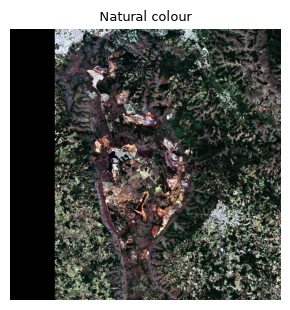

In [30]:
clear = ~ds["scl"].isin([0, 1, 3, 8, 9, 10, 11])
bands = ds.drop_vars("scl").map(lambda band: rb.dn_to_reflectance(band, sensor)).where(clear)

rb.plot_composites({"natural_colour": rb.natural_colour(bands, sensor=sensor)}, ncols=1);

## 5. Run one ratio

Every ratio is a function. Pass the scene and the sensor and the library finds the bands it needs. `ferric_iron_redness` is red over blue (`R/B`), high where iron oxides stain the surface.

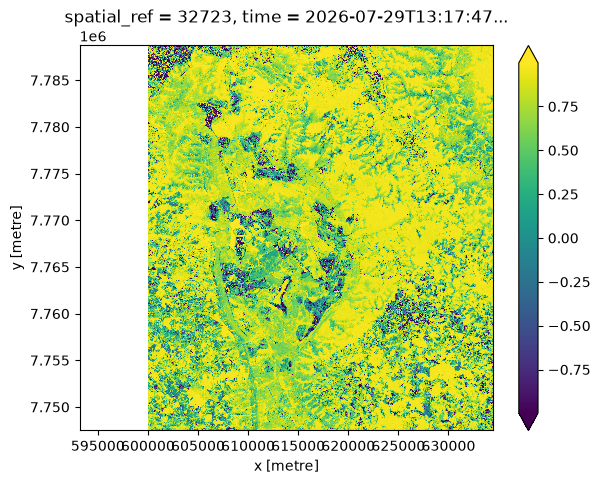

In [31]:
ferric = rb.ferric_iron_redness(bands, sensor=sensor)
ferric.plot.imshow(robust=True, cmap="viridis", size=5);

`translate` writes the formula in this sensor's own band ids, and the sensor module accepts those ids directly.

In [32]:
print(rb.translate("ferric_iron_redness", sensor))

rb.sensors.s2.ferric_iron_redness(B4=bands.B4, B2=bands.B2).equals(ferric)

B4/B2


True

## 6. See what Sentinel-2 can run

A ratio runs only if the sensor has every band it needs. This table lists the ratios Sentinel-2 can run and the formula it evaluates in Sentinel-2 band ids. The 25 ASTER-specific ratios are not here: they use ASTER's narrow SWIR and thermal bands (see the ASTER notebook).

In [33]:
pd.DataFrame(
    [(r.name, r.formula, rb.translate(r, sensor)) for r in rb.list_ratios(sensor, kind="ratio")],
    columns=["ratio", "formula", "sentinel2_bands"],
)

,ratio,formula,sentinel2_bands
0,ferric_iron_redness,R/B,B4/B2
1,ferric_iron_2,(R/B)*((R+S1)/N),(B4/B2)*((B4+B11)/B8)
2,ferrous_iron,(G+S1)/(R+N),(B3+B11)/(B4+B8)
3,clay_sulphate_mica_marble,(S1/S2)/(N/R),(B11/B12)/(B8/B4)
4,iron_sulphate,(B/A)-(N/R),(B2/B1)-(B8/B4)
5,ndvi,(N-R)/(N+R),(B8-B4)/(B8+B4)
6,moisture_index,(N2-S1)/(N2+S1),(B8A-B11)/(B8A+B11)
7,ndwi,(G-N)/(G+N),(B3-B8)/(B3+B8)


## 7. Run every ratio and composite

`compute_all` evaluates everything the sensor supports and returns a dictionary, ready for the plotting helpers. Each map is stretched between its 2nd and 98th percentile.

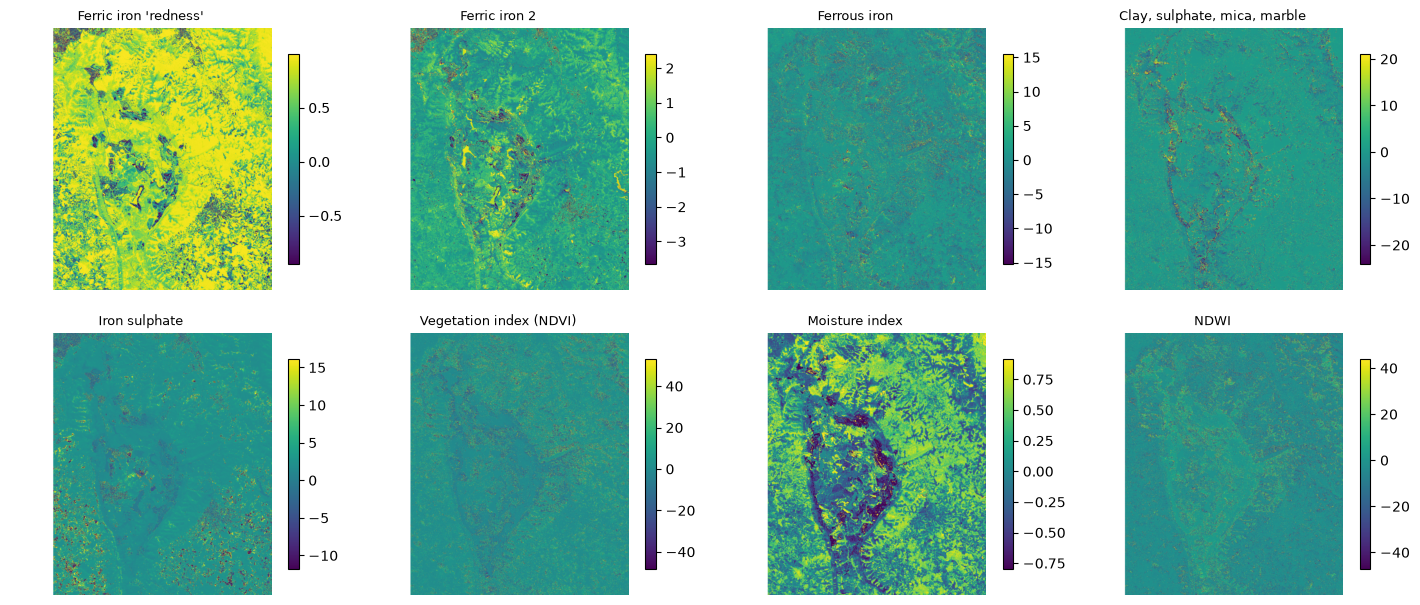

In [34]:
ratios = rb.compute_all(bands, sensor, kind="ratio")
rb.plot_ratios(ratios, ncols=4);

RGB composites place three bands, or three ratios, in the red, green and blue channels. Each channel is stretched on its own.

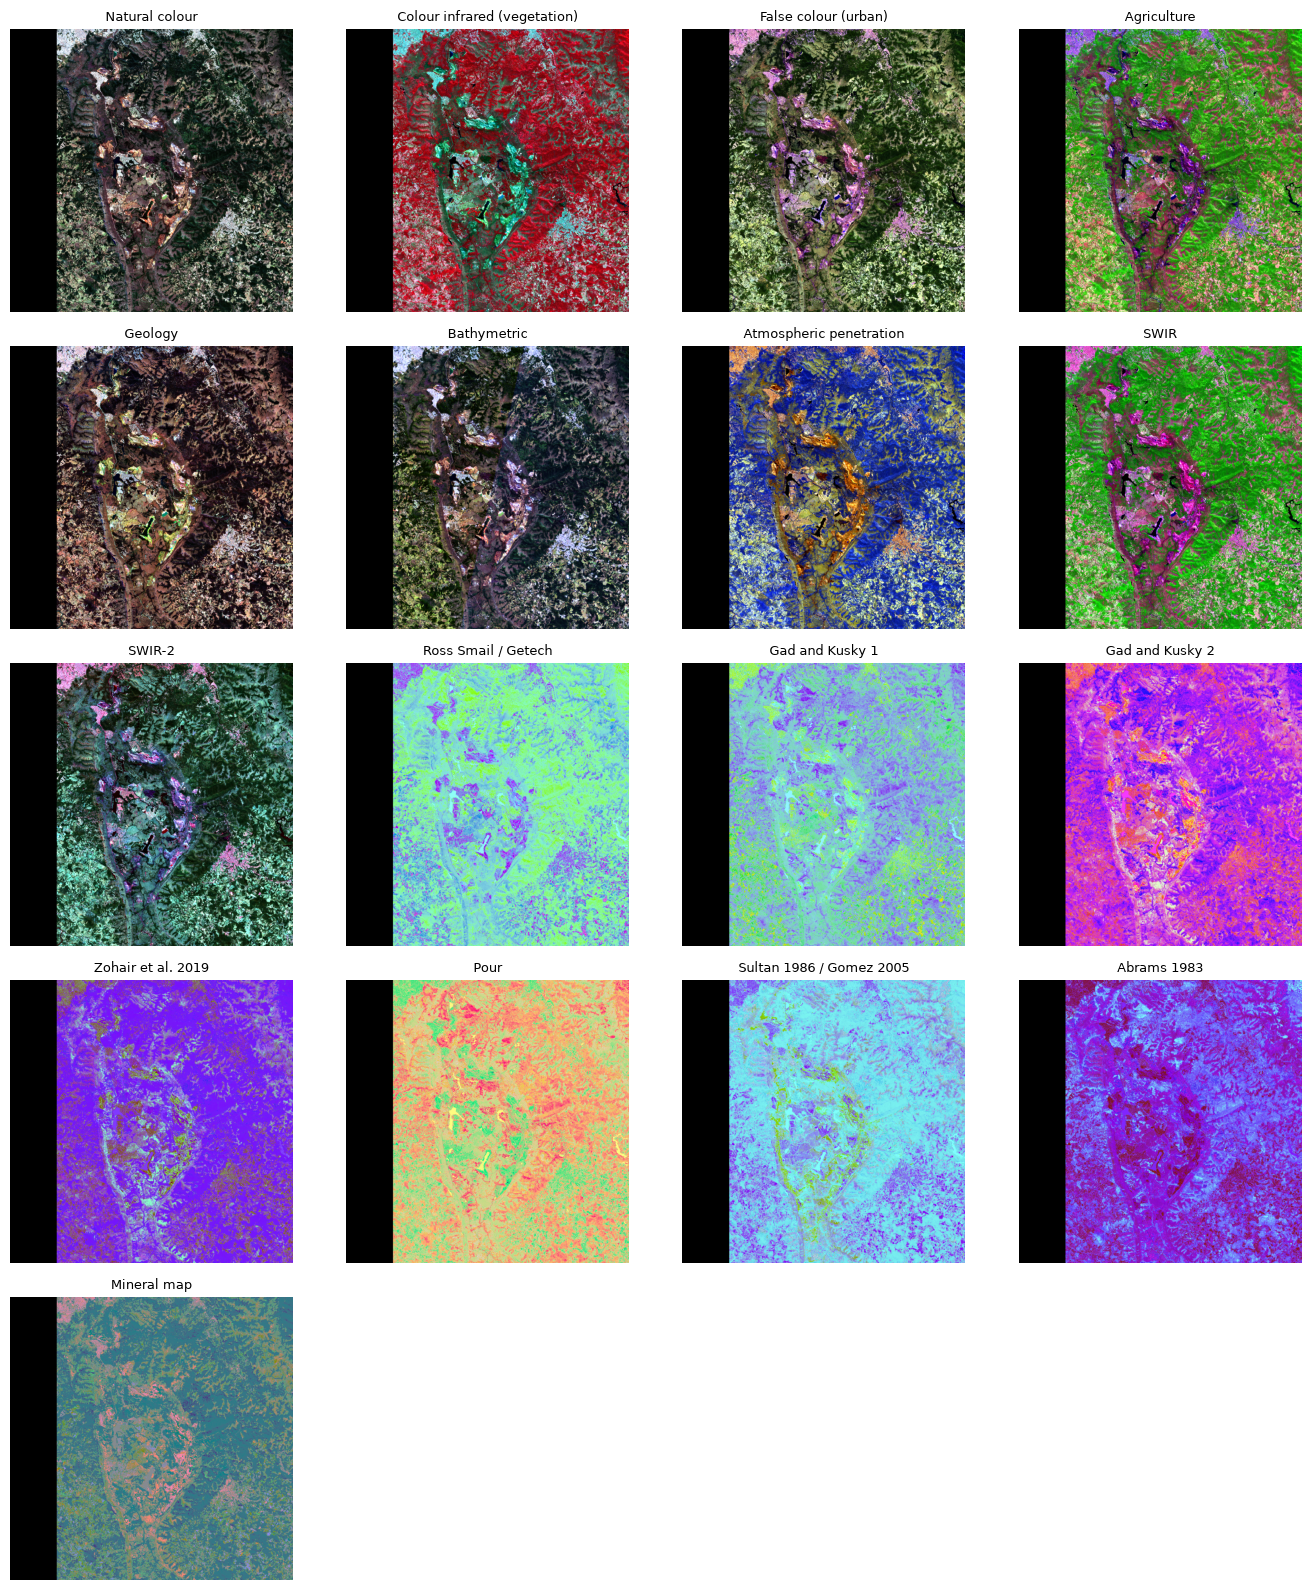

In [35]:
composites = rb.compute_all(bands, sensor, kind="composite")
rb.plot_composites(composites, ncols=4);

## 8. Use your own formula and save a result

Any formula written with standard band names (`A B G R RE1 RE2 RE3 N N2 S1 S2`) runs on any sensor that has those bands. Results are xarray objects, so they keep their coordinates and can be written straight to GeoTIFF.

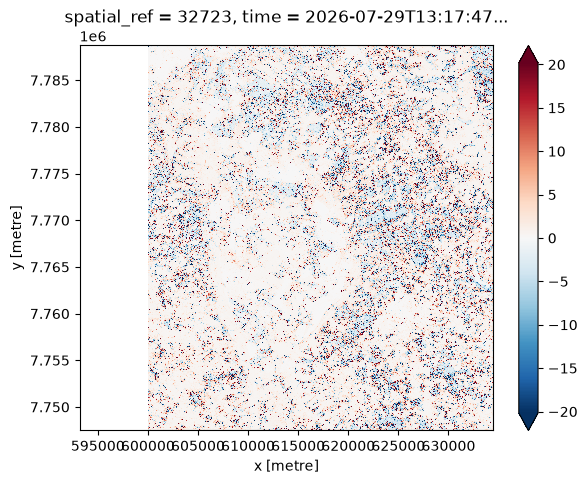

In [36]:
swir_difference = rb.evaluate_formula("(S1-S2)/(S1+S2)", bands, sensor=sensor)
swir_difference.plot.imshow(robust=True, size=5)

ferric.rio.write_nodata(float("nan")).rio.to_raster("ferric_iron_redness_s2.tif")

## 9. Compare with Landsat

The same ratio on Sentinel-2 and Landsat 8 targets the same spectral region but uses bands of different width. `spectral_equivalence` quantifies it: *IoU* is the overlap of the two bands relative to their combined range, *midpoint shift* is how far their centres are apart. The NIR band differs most, so calibrate before mixing sensors in one analysis.

In [37]:
rb.spectral_equivalence("s2", "l8")

**Spectral equivalence: Sentinel-2 MSI vs Landsat 8 OLI/TIRS**

| Role | s2 | l8 | Overlap (nm) | % of s2 | % of l8 | IoU | Midpoint shift (nm) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| A | B1 | B1 | 17.3 | 87% | 87% | 0.76 | -3 |
| B | B2 | B2 | 49.8 | 77% | 83% | 0.66 | -13 |
| G | B3 | B3 | 35 | 100% | 58% | 0.58 | +0 |
| R | B4 | B4 | 20.4 | 68% | 68% | 0.52 | -10 |
| N | B8 | B5 | 30 | 29% | 100% | 0.29 | +32 |
| S1 | B11 | B6 | 80 | 89% | 100% | 0.89 | -4 |
| S2 | B12 | B7 | 174 | 100% | 97% | 0.97 | -2 |